# Euro 2020 EDA (lineups_df + matches_df)
- Loads CSVs
- Validates keys & joins
- Parses nested columns (positions, cards)
- Comprehensive EDA for matches, teams, players
- Visualizations (matplotlib)


In [2]:
# %% 
import json
import math
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (10, 5)


Matplotlib is building the font cache; this may take a moment.


## Helper Functions

In [3]:
# %%
def df_quick_summary(df: pd.DataFrame, name: str = "df") -> None:
    print(f"== {name} ==")
    print(f"shape: {df.shape}")
    print("\ncolumns:")
    print(df.columns.tolist())
    print("\ndtypes:")
    print(df.dtypes)
    print("\nmissing (%):")
    miss = df.isna().mean().sort_values(ascending=False) * 100
    print(miss.to_string(float_format=lambda x: f"{x:0.2f}"))
    print("\nunique counts (head):")
    nun = df.nunique(dropna=True).sort_values(ascending=False)
    print(nun.head(20))
    print("\nmemory usage (MB):")
    print(round(df.memory_usage(deep=True).sum() / 1_048_576, 2))


In [4]:
# %%
def try_json_loads(x: Any) -> Optional[Any]:
    """Safely parse JSON-like strings; return None on failure."""
    if pd.isna(x):
        return None
    if isinstance(x, (dict, list)):
        return x
    s = str(x).strip()
    # Sometimes single quotes are used; make a best-effort normalization
    if s and s[0] in "[{(" and s[-1] in "]})":
        try:
            return json.loads(s.replace("'", '"'))
        except Exception:
            pass
    # Try a plain json.loads fallback
    try:
        return json.loads(s)
    except Exception:
        return None


In [5]:
# %%
def hms_to_minutes(s: Optional[str]) -> Optional[float]:
    """Convert 'HH:MM:SS' or 'MM:SS' to minutes (float)."""
    if not s or not isinstance(s, str):
        return None
    parts = s.split(":")
    try:
        if len(parts) == 3:
            h, m, sec = map(float, parts)
            return h * 60 + m + sec / 60
        elif len(parts) == 2:
            m, sec = map(float, parts)
            return m + sec / 60
    except Exception:
        return None
    return None


## 1) load data

In [6]:
# %% 
LINEUPS_CSV = "lineups_df.csv"
MATCHES_CSV = "matches_df.csv"

lineups = pd.read_csv(LINEUPS_CSV)
matches = pd.read_csv(MATCHES_CSV)


In [7]:
# %%
df_quick_summary(lineups, "lineups")
df_quick_summary(matches, "matches")


== lineups ==
shape: (2345, 10)

columns:
['id', 'match_id', 'player_id', 'player_name', 'player_nickname', 'jersey_number', 'country', 'cards', 'positions', 'team_name']

dtypes:
id                  int64
match_id            int64
player_id           int64
player_name        object
player_nickname    object
jersey_number       int64
country            object
cards              object
positions          object
team_name          object
dtype: object

missing (%):
player_nickname   80.09
id                 0.00
match_id           0.00
player_id          0.00
player_name        0.00
jersey_number      0.00
country            0.00
cards              0.00
positions          0.00
team_name          0.00

unique counts (head):
id                 2345
positions          1047
player_id           612
player_name         612
cards               156
player_nickname     106
match_id             51
jersey_number        26
country              25
team_name            24
dtype: int64

memory usage (M

## 2) key integrity & basic validation

In [8]:
# %% 
# Confirm key columns exist
assert "match_id" in lineups.columns, "lineups missing `match_id`"
assert "match_id" in matches.columns, "matches missing `match_id`"

# matches should have unique match_id
print("matches.match_id unique?:", matches["match_id"].is_unique)

# any duplicate player rows within a match?
dupes_match_player = lineups.duplicated(subset=["match_id", "player_id"], keep=False)
print("duplicate (match_id, player_id) rows:", dupes_match_player.sum())

# team presence per match in lineups
teams_per_match = (
    lineups.groupby("match_id")["team_name"].nunique(dropna=True).rename("teams_in_lineups")
)
print(teams_per_match.describe())
print("sample of matches where teams_in_lineups != 2:")
print(teams_per_match[teams_per_match != 2].head(10))


matches.match_id unique?: True
duplicate (match_id, player_id) rows: 0
count    51.0
mean      2.0
std       0.0
min       2.0
25%       2.0
50%       2.0
75%       2.0
max       2.0
Name: teams_in_lineups, dtype: float64
sample of matches where teams_in_lineups != 2:
Series([], Name: teams_in_lineups, dtype: int64)


In [9]:
# %% 
# How many lineup rows per match? (sanity: around squad size)
lineup_rows_per_match = lineups.groupby("match_id").size()
print(lineup_rows_per_match.describe())


count    51.000000
mean     45.980392
std       0.140028
min      45.000000
25%      46.000000
50%      46.000000
75%      46.000000
max      46.000000
dtype: float64


## 3) parse nested columns (positions, cards)

In [10]:
# %% 
has_positions = "positions" in lineups.columns
has_cards = "cards" in lineups.columns

if has_positions:
    lineups["positions_parsed"] = lineups["positions"].apply(try_json_loads)
else:
    lineups["positions_parsed"] = None

if has_cards:
    lineups["cards_parsed"] = lineups["cards"].apply(try_json_loads)
else:
    lineups["cards_parsed"] = None

# Identify starters (heuristic): any segment starting from 00:00:00 OR start_reason present
def is_starter(pos_list: Any) -> Optional[bool]:
    if not isinstance(pos_list, list):
        return None
    for seg in pos_list:
        start = seg.get("from") if isinstance(seg, dict) else None
        start_reason = seg.get("start_reason") if isinstance(seg, dict) else None
        if start == "00:00:00" or (start_reason not in (None, "", np.nan)):
            return True
    return False

# Minutes played estimate from segments
def minutes_played(pos_list: Any) -> Optional[float]:
    if not isinstance(pos_list, list):
        return None
    total = 0.0
    for seg in pos_list:
        if not isinstance(seg, dict):
            continue
        start = hms_to_minutes(seg.get("from"))
        end = hms_to_minutes(seg.get("to"))
        if start is not None and end is not None:
            total += max(0.0, end - start)
    return total if total > 0 else None

lineups["is_starter"] = lineups["positions_parsed"].apply(is_starter)
lineups["minutes_played"] = lineups["positions_parsed"].apply(minutes_played)

# Cards exploded
def explode_cards(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for r in df.itertuples(index=False):
        cards = getattr(r, "cards_parsed", None)
        if isinstance(cards, list) and cards:
            for c in cards:
                if isinstance(c, dict):
                    rows.append({
                        "match_id": getattr(r, "match_id", None),
                        "team_name": getattr(r, "team_name", None),
                        "player_id": getattr(r, "player_id", None),
                        "player_name": getattr(r, "player_name", None),
                        "card_type": c.get("type") or c.get("card_type"),
                        "card_time_hms": c.get("time") or c.get("minute") or c.get("card_time"),
                        "reason": c.get("reason")
                    })
    return pd.DataFrame(rows)

cards_long = explode_cards(lineups) if has_cards else pd.DataFrame(columns=[
    "match_id", "team_name", "player_id", "player_name", "card_type", "card_time_hms", "reason"
])


In [11]:
cards_long

,match_id,team_name,player_id,player_name,card_type,card_time_hms,reason
0,3788741,Turkey,8963,Caglar Söyüncü,Yellow Card,87:18,Foul Committed
1,3788741,Turkey,21567,İbrahim Halil Dervişoğlu,Yellow Card,89:00,Foul Committed
2,3788742,Finland,24321,Robin Lod,Yellow Card,03:38,Foul Committed
3,3788742,Finland,24648,Tim Sparv,Yellow Card,50:37,Foul Committed
4,3788744,Wales,3853,Kieffer Roberto Francisco Moore,Yellow Card,46:23,Foul Committed
...,...,...,...,...,...,...,...
151,3795506,Italy,7024,Jorge Luiz Frello Filho,Yellow Card,11:16,Foul Committed
152,3795506,Italy,7037,Lorenzo Insigne,Yellow Card,83:39,Foul Committed
153,3795506,Italy,7173,Leonardo Bonucci,Yellow Card,54:27,Foul Committed
154,3795506,Italy,8181,Nicolò Barella,Yellow Card,46:36,Foul Committed


## 4) enrich matches + time columns

In [12]:
# %% 
# Basic time handling: combine match_date + kick_off if present
matches["match_date"] = pd.to_datetime(matches.get("match_date", pd.NaT), errors="coerce")
# some datasets store kick_off as HH:MM:SS
if "kick_off" in matches.columns:
    # keep as text; we’ll build a datetime if possible
    ko_time = pd.to_datetime(matches["kick_off"], errors="coerce").dt.time
    matches["kick_off_time"] = ko_time
else:
    matches["kick_off_time"] = None

# Combined datetime (naive)
def combine_datetime(row):
    d = row.get("match_date")
    t = row.get("kick_off_time")
    if pd.isna(d) or t is None or pd.isna(pd.to_datetime(d, errors="coerce")):
        return pd.NaT
    return pd.to_datetime(str(pd.to_datetime(d).date()) + " " + str(t), errors="coerce")

matches["match_datetime"] = matches.apply(combine_datetime, axis=1)


/var/folders/np/nf0l0rsx3wn2wmcw1dh1xrhc0000gn/T/ipykernel_38131/1317810880.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ko_time = pd.to_datetime(matches["kick_off"], errors="coerce").dt.time


In [14]:
matches['match_datetime']

0    2021-07-02 18:00:00
1    2021-06-21 21:00:00
2    2021-06-20 18:00:00
3    2021-07-06 21:00:00
4    2021-06-18 15:00:00
5    2021-06-19 18:00:00
6    2021-06-23 21:00:00
7    2021-06-16 18:00:00
8    2021-06-16 21:00:00
9    2021-06-19 21:00:00
10   2021-06-18 18:00:00
11   2021-06-13 18:00:00
12   2021-06-11 21:00:00
13   2021-07-03 18:00:00
14   2021-07-03 21:00:00
15   2021-06-21 18:00:00
16   2021-07-11 21:00:00
17   2021-06-29 18:00:00
18   2021-06-29 21:00:00
19   2021-06-28 18:00:00
20   2021-06-27 21:00:00
21   2021-06-26 21:00:00
22   2021-06-23 21:00:00
23   2021-06-22 21:00:00
24   2021-06-22 21:00:00
25   2021-06-21 21:00:00
26   2021-06-21 18:00:00
27   2021-06-16 15:00:00
28   2021-06-20 18:00:00
29   2021-06-19 15:00:00
30   2021-06-18 21:00:00
31   2021-06-17 15:00:00
32   2021-06-17 18:00:00
33   2021-06-13 15:00:00
34   2021-07-02 21:00:00
35   2021-07-07 21:00:00
36   2021-06-26 18:00:00
37   2021-06-13 21:00:00
38   2021-06-28 21:00:00
39   2021-06-27 18:00:00


## 5) merge lineups + matches and add home/away side

In [15]:
# %% 
mcols_keep = [
    "match_id","match_date","match_datetime","competition","season",
    "home_team","away_team","home_score","away_score"
]
mcols_keep = [c for c in mcols_keep if c in matches.columns]

lm = lineups.merge(matches[mcols_keep], on="match_id", how="left")

# Side label (home/away) based on team_name matching
def infer_side(row) -> Optional[str]:
    t = row.get("team_name")
    h = row.get("home_team")
    a = row.get("away_team")
    if pd.isna(t) or (pd.isna(h) and pd.isna(a)):
        return None
    if t == h:
        return "home"
    if t == a:
        return "away"
    return None

lm["side"] = lm.apply(infer_side, axis=1)


In [16]:
lm

,id,match_id,player_id,player_name,player_nickname,jersey_number,country,cards,positions,team_name,positions_parsed,cards_parsed,is_starter,minutes_played,match_date,match_datetime,competition,season,home_team,away_team,home_score,away_score,side
0,1,3788741,4355,Emerson Palmieri dos Santos,Emerson,13,Italy,[],[],Italy,[],[],False,NaN,2021-06-11,2021-06-11 21:00:00,Europe - UEFA Euro,2020,Turkey,Italy,0,3,away
1,2,3788741,6954,Giorgio Chiellini,NaN,3,Italy,[],"[{""end_reason"": ""Final Whistle"", ""from"": ""00:0...",Italy,"[{'end_reason': 'Final Whistle', 'from': '00:0...",[],True,NaN,2021-06-11,2021-06-11 21:00:00,Europe - UEFA Euro,2020,Turkey,Italy,0,3,away
2,3,3788741,6957,Alex Meret,NaN,26,Italy,[],[],Italy,[],[],False,NaN,2021-06-11,2021-06-11 21:00:00,Europe - UEFA Euro,2020,Turkey,Italy,0,3,away
3,4,3788741,6964,Alessandro Florenzi,NaN,24,Italy,[],"[{""end_reason"": ""Substitution - Off (Tactical)...",Italy,[{'end_reason': 'Substitution - Off (Tactical)...,[],True,45.000000,2021-06-11,2021-06-11 21:00:00,Europe - UEFA Euro,2020,Turkey,Italy,0,3,away
4,5,3788741,6993,Bryan Cristante,NaN,16,Italy,[],"[{""end_reason"": ""Final Whistle"", ""from"": ""73:1...",Italy,"[{'end_reason': 'Final Whistle', 'from': '73:1...",[],True,NaN,2021-06-11,2021-06-11 21:00:00,Europe - UEFA Euro,2020,Turkey,Italy,0,3,away
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2340,2341,3795506,10955,Harry Kane,NaN,9,England,[],"[{""end_reason"": ""Final Whistle"", ""from"": ""00:0...",England,"[{'end_reason': 'Final Whistle', 'from': '00:0...",[],True,NaN,2021-07-11,2021-07-11 21:00:00,Europe - UEFA Euro,2020,Italy,England,1,1,away
2341,2342,3795506,12423,Jadon Sancho,NaN,17,England,[],"[{""end_reason"": ""Tactical Shift"", ""from"": ""119...",England,"[{'end_reason': 'Tactical Shift', 'from': '119...",[],True,1.716667,2021-07-11,2021-07-11 21:00:00,Europe - UEFA Euro,2020,Italy,England,1,1,away
2342,2343,3795506,22084,Bukayo Saka,NaN,25,England,[],"[{""end_reason"": ""Tactical Shift"", ""from"": ""100...",England,"[{'end_reason': 'Tactical Shift', 'from': '100...",[],True,21.650000,2021-07-11,2021-07-11 21:00:00,Europe - UEFA Euro,2020,Italy,England,1,1,away
2343,2344,3795506,22783,Aaron Ramsdale,NaN,13,England,[],[],England,[],[],False,NaN,2021-07-11,2021-07-11 21:00:00,Europe - UEFA Euro,2020,Italy,England,1,1,away


## 6) matches EDA

result
Away Win    22
Home Win    17
Draw        12
Name: count, dtype: int64

Top scorelines:
home_score  away_score
1           1             7
            0             5
            2             5
0           2             4
            1             4
3           1             3
0           3             3
2           1             3
0           0             2
            4             2
dtype: int64

Goals per match summary:
count    51.000000
mean      2.784314
std       1.616338
min       0.000000
25%       2.000000
50%       3.000000
75%       4.000000
max       8.000000
Name: goals_total, dtype: float64


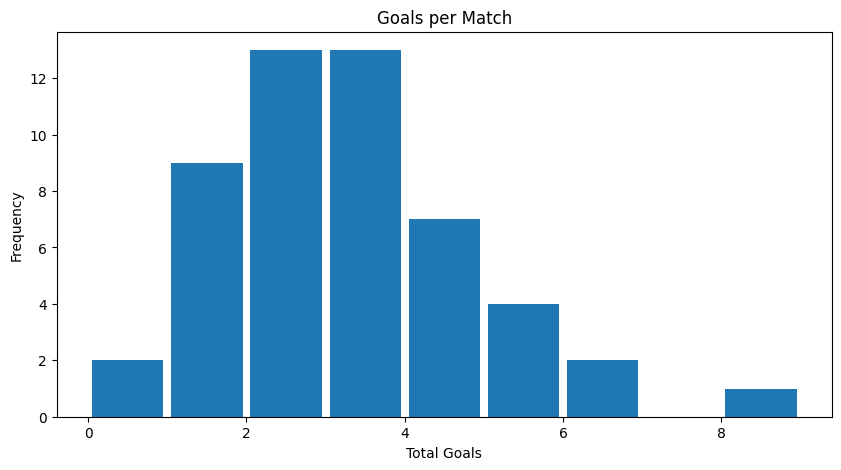

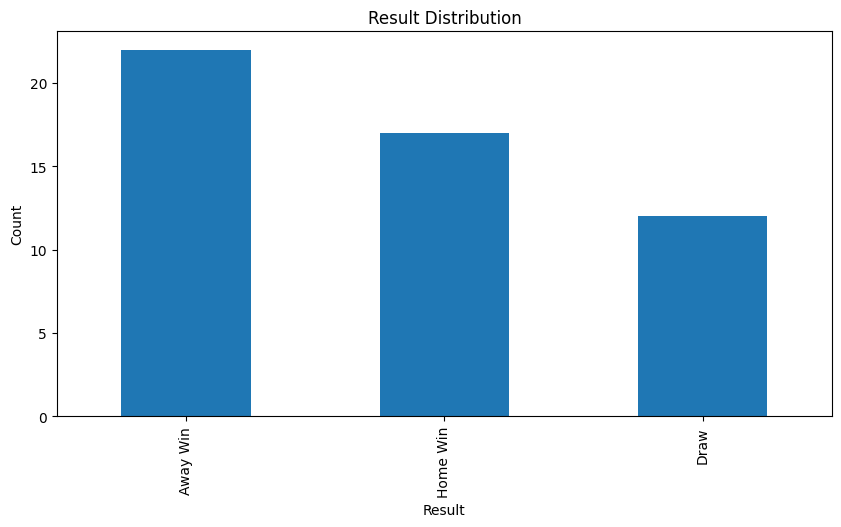

In [17]:
# %% 
# Basic outcomes
matches["goal_diff"] = matches["home_score"] - matches["away_score"]
matches["result"] = np.where(matches["goal_diff"] > 0, "Home Win",
                      np.where(matches["goal_diff"] < 0, "Away Win", "Draw"))

print(matches["result"].value_counts(dropna=False))
print("\nTop scorelines:")
print(matches.groupby(["home_score","away_score"]).size().sort_values(ascending=False).head(10))

# Goals per match
matches["goals_total"] = matches["home_score"] + matches["away_score"]
print("\nGoals per match summary:")
print(matches["goals_total"].describe())

# Plots
matches["goals_total"].plot(kind="hist", bins=range(0, matches["goals_total"].max()+2), rwidth=0.9)
plt.title("Goals per Match")
plt.xlabel("Total Goals")
plt.ylabel("Frequency")
plt.show()

matches["result"].value_counts().plot(kind="bar")
plt.title("Result Distribution")
plt.xlabel("Result")
plt.ylabel("Count")
plt.show()


                 gf  ga  gd
team                       
Italy            13   4   9
England          11   2   9
Spain            13   6   7
Belgium           9   3   6
Denmark          12   7   5
Netherlands       8   4   4
Czech Republic    6   4   2
France            7   6   1
Sweden            5   4   1
Portugal          7   7   0
Austria           5   5   0
Switzerland       8   9  -1
Croatia           7   8  -1
Germany           6   7  -1
Poland            4   6  -2
Finland           1   3  -2
Hungary           3   6  -3
Wales             3   6  -3
Ukraine           6  10  -4
Scotland          1   5  -4
Russia            2   7  -5
Slovakia          2   7  -5
North Macedonia   2   8  -6
Turkey            1   8  -7


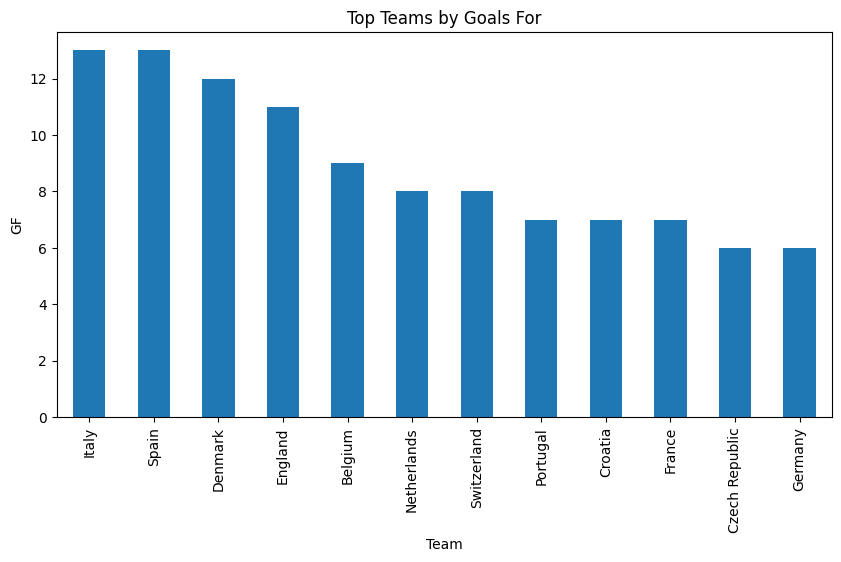

In [20]:
# %% 
# Team-level goal for/against
team_goals = pd.concat([
    matches[["home_team","home_score","away_score"]].rename(columns={"home_team":"team","home_score":"gf","away_score":"ga"}),
    matches[["away_team","away_score","home_score"]].rename(columns={"away_team":"team","away_score":"gf","home_score":"ga"})
], axis=0, ignore_index=True)

team_goals_agg = team_goals.groupby("team").agg(gf=("gf","sum"), ga=("ga","sum"))
team_goals_agg["gd"] = team_goals_agg["gf"] - team_goals_agg["ga"]
team_goals_agg = team_goals_agg.sort_values(["gd","gf"], ascending=[False, False])
print(team_goals_agg)

team_goals_agg["gf"].sort_values(ascending=False).head(12).plot(kind="bar")
plt.title("Top Teams by Goals For")
plt.xlabel("Team")
plt.ylabel("GF")
plt.show()


## 7) lineups EDA (players/teams per match)

    match_id team_name  squad_size
0    3788741     Italy          23
64   3788773    France          23
74   3794686   Croatia          23
73   3794685     Italy          23
72   3794685   Austria          23
71   3788776    Sweden          23
70   3788776    Poland          23
69   3788775     Spain          23
68   3788775  Slovakia          23
67   3788774   Hungary          23


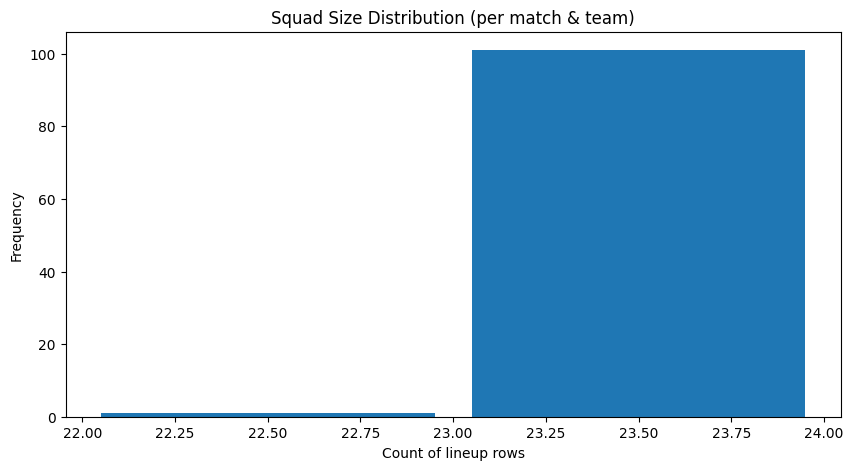

In [21]:
# %% 
# Roster counts per team/match
roster_counts = lm.groupby(["match_id","team_name"]).size().rename("squad_size").reset_index()
print(roster_counts.sort_values("squad_size", ascending=False).head(10))

roster_counts["squad_size"].plot(kind="hist", bins=range(int(roster_counts["squad_size"].min()), int(roster_counts["squad_size"].max())+2), rwidth=0.9)
plt.title("Squad Size Distribution (per match & team)")
plt.xlabel("Count of lineup rows")
plt.ylabel("Frequency")
plt.show()


     match_id    team_name  starters
101   3795506        Italy        17
91    3795108  Switzerland        17
72    3794685      Austria        17
75    3794686        Spain        17
85    3794691  Switzerland        17
86    3794692       Sweden        17
87    3794692      Ukraine        17
90    3795108        Spain        17
74    3794686      Croatia        17
96    3795220        Italy        17


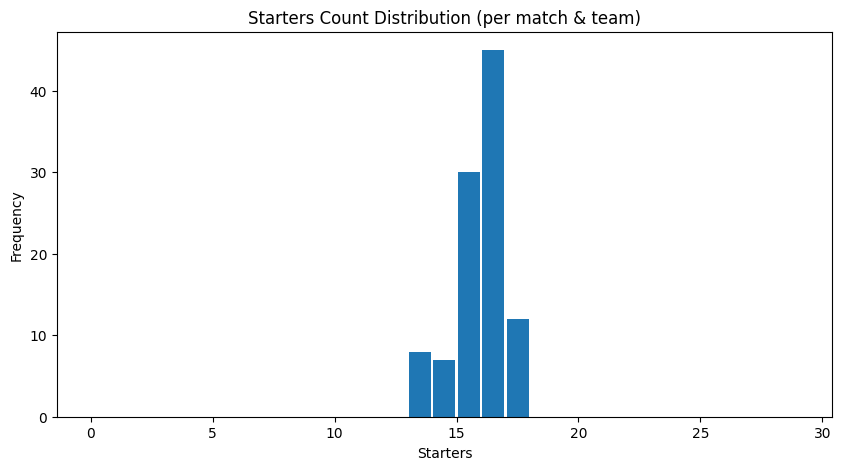

In [22]:
# %% 
# Starters per team/match (if 'positions' parsed)
if "is_starter" in lm.columns:
    starters_counts = lm.groupby(["match_id","team_name"])["is_starter"].sum(min_count=1).rename("starters").reset_index()
    print(starters_counts.sort_values("starters", ascending=False).head(10))

    starters_counts["starters"].plot(kind="hist", bins=range(0, 30), rwidth=0.9)
    plt.title("Starters Count Distribution (per match & team)")
    plt.xlabel("Starters")
    plt.ylabel("Frequency")
    plt.show()


weird?

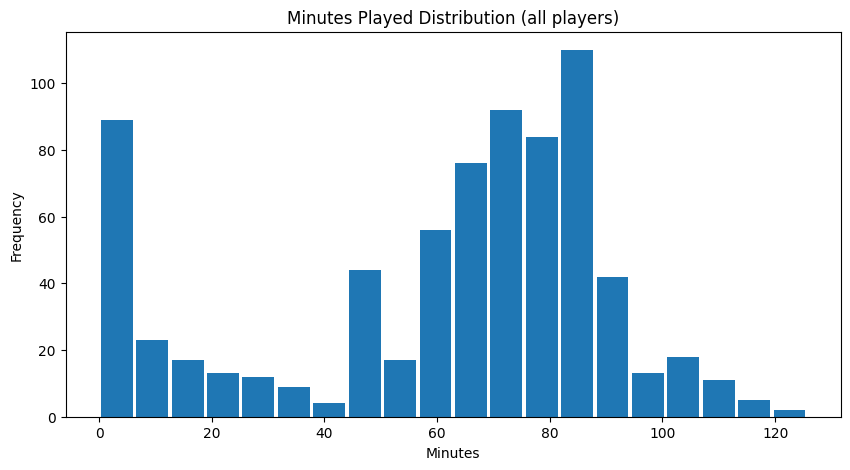

count    737.000000
mean      60.601560
std       30.834670
min        0.016667
25%       45.000000
50%       69.450000
75%       83.166667
max      125.683333
Name: minutes_played, dtype: float64


In [23]:
# %% 
# Minutes played distribution (if available)
if "minutes_played" in lm.columns:
    mp = lm["minutes_played"].dropna()
    if not mp.empty:
        mp.plot(kind="hist", bins=20, rwidth=0.9)
        plt.title("Minutes Played Distribution (all players)")
        plt.xlabel("Minutes")
        plt.ylabel("Frequency")
        plt.show()
        print(mp.describe())


In [27]:
# %% 
# Player appearance counts across the tournament
player_apps = lm.groupby(["player_id","player_name"]).size().rename("appearances").reset_index()
print(player_apps.sort_values("appearances", ascending=False).head(20))

     player_id                  player_name  appearances
100       4706              Kalvin Phillips            7
354      10955                   Harry Kane            7
226       7036         Gianluigi Donnarumma            7
227       7037              Lorenzo Insigne            7
376      11601               Matteo Pessina            7
25        3233              Raheem Sterling            7
26        3244                  John Stones            7
228       7038             Manuel Locatelli            7
374      11514          Giovanni Di Lorenzo            7
240       7480           Alessandro Bastoni            7
239       7471               Andrea Belotti            7
31        3308              Kieran Trippier            7
232       7119             Francesco Acerbi            7
33        3318              Marcus Rashford            7
238       7469             Salvatore Sirigu            7
235       7156              Federico Chiesa            7
36        3323                 

team_name
Italy              25
Belgium            24
Austria            22
France             21
Ukraine            21
Spain              21
Netherlands        21
North Macedonia    21
England            21
Denmark            21
Czech Republic     21
Croatia            21
Portugal           20
Russia             20
Scotland           20
Slovakia           20
Switzerland        20
Germany            19
Finland            19
Poland             19
Sweden             19
Hungary            18
Turkey             18
Wales              18
Name: unique_starters_overall, dtype: int64
          team_name  match_id                                     starters_tuple                                         prev_tuple  starter_similarity_prev
7           Belgium   3794687  (20005, 2954, 3077, 3089, 3176, 3289, 3509, 36...  (13116, 16281, 16559, 23650, 3089, 3176, 3289,...                 0.318182
47            Italy   3788766  (11601, 25048, 30707, 3166, 4355, 6993, 7002, ...  (11514, 11601, 6954, 6

/var/folders/np/nf0l0rsx3wn2wmcw1dh1xrhc0000gn/T/ipykernel_38131/4273872714.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  starters_by_match = lm.groupby(["team_name","match_id"]).apply(starters_key).rename("starters_tuple").reset_index()


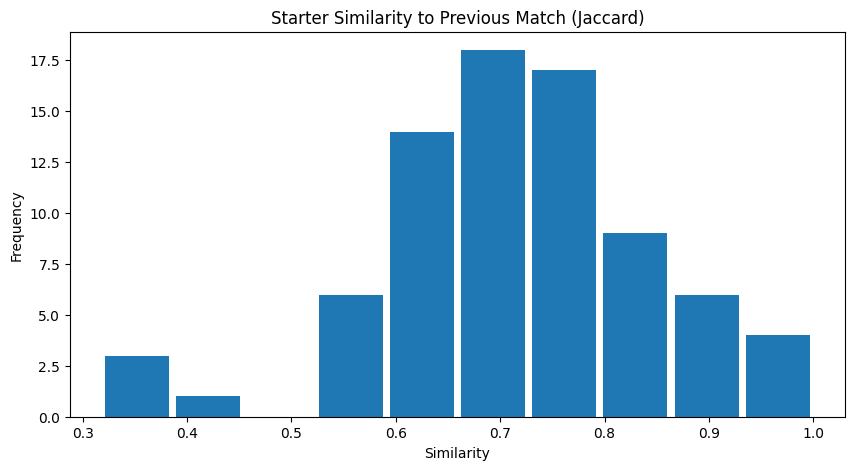

In [28]:
# %% 
# Team lineup stability: number of unique starters (if available) and churn between matches
if "is_starter" in lm.columns:
    starters_only = lm[lm["is_starter"] == True]
    team_starter_pool = starters_only.groupby("team_name")["player_id"].nunique().rename("unique_starters_overall")
    print(team_starter_pool.sort_values(ascending=False))

    # change in starters match-to-match (roughly)
    def starters_key(df):
        return tuple(sorted(df.loc[df["is_starter"] == True, "player_id"].astype(str).tolist()))

    starters_by_match = lm.groupby(["team_name","match_id"]).apply(starters_key).rename("starters_tuple").reset_index()
    starters_by_match["prev_tuple"] = starters_by_match.groupby("team_name")["starters_tuple"].shift(1)
    def jaccard(a, b):
        if not isinstance(a, tuple) or not isinstance(b, tuple):
            return np.nan
        A, B = set(a), set(b)
        if not A and not B:
            return np.nan
        return len(A & B) / len(A | B)
    starters_by_match["starter_similarity_prev"] = starters_by_match.apply(lambda r: jaccard(r["starters_tuple"], r["prev_tuple"]), axis=1)
    print(starters_by_match.dropna(subset=["starter_similarity_prev"]).sort_values("starter_similarity_prev").head(20))

    starters_by_match["starter_similarity_prev"].plot(kind="hist", bins=10, rwidth=0.9)
    plt.title("Starter Similarity to Previous Match (Jaccard)")
    plt.xlabel("Similarity")
    plt.ylabel("Frequency")
    plt.show()


## 8) cards analysis (if present)

card_type
Yellow Card      150
Red Card           5
Second Yellow      1
Name: count, dtype: int64

Cards by team:
card_type        Red Card  Second Yellow  Yellow Card
team_name                                            
Austria                 0              0            6
Belgium                 0              0            4
Croatia                 0              0            7
Czech Republic          0              0            7
Denmark                 0              0            5
England                 0              0            6
Finland                 0              0            4
France                  0              0            8
Germany                 0              0            7
Hungary                 0              0            6
Italy                   0              0           12
Netherlands             1              0            3
North Macedonia         0              0            8
Poland                  0              1            7
Portugal             

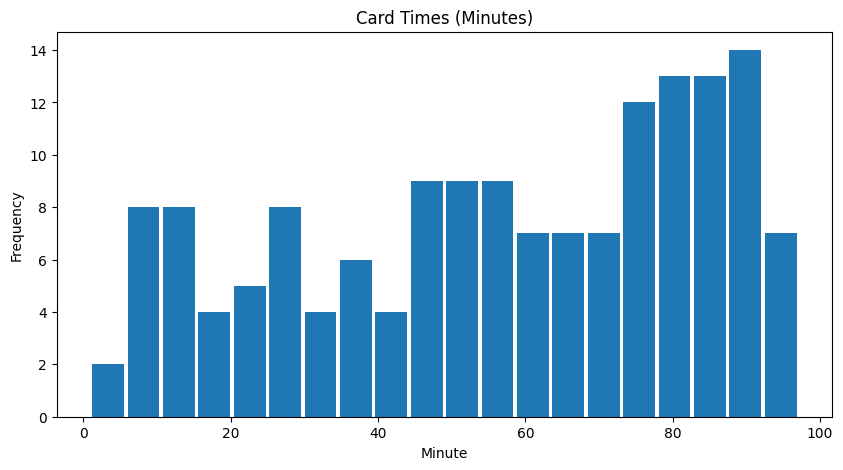

In [29]:
# %% 
if not cards_long.empty:
    print(cards_long["card_type"].value_counts(dropna=False))
    print("\nCards by team:")
    print(cards_long.groupby("team_name")["card_type"].value_counts().unstack(fill_value=0).sort_index())

    # Approximate minute from time string
    cards_long["minute"] = cards_long["card_time_hms"].apply(hms_to_minutes)
    cards_long["minute"].plot(kind="hist", bins=20, rwidth=0.9)
    plt.title("Card Times (Minutes)")
    plt.xlabel("Minute")
    plt.ylabel("Frequency")
    plt.show()


## 9) nulls, outliers, and consistency checks

In [32]:
# %% 
# Missing critical fields
crit_fields = ["match_id","team_name","player_id","player_name"]
present_crit = [c for c in crit_fields if c in lm.columns]
print(lm[present_crit].isna().mean().sort_values(ascending=False))

# Players without positions or minutes (if applicable)
if "positions_parsed" in lm.columns:
    print("Rows with no positions parsed:", lm["positions_parsed"].isna().sum())

if "minutes_played" in lm.columns:
    mp = lm["minutes_played"].dropna()
    if not mp.empty:
        print("Minutes outside [0, 130] (sanity for tournaments with ET):")
        bad = lm[(lm["minutes_played"] < 0) | (lm["minutes_played"] > 130)]
        print(bad[["match_id","team_name","player_name","minutes_played"]].head(20))


match_id       0.0
team_name      0.0
player_id      0.0
player_name    0.0
dtype: float64
Rows with no positions parsed: 0
Minutes outside [0, 130] (sanity for tournaments with ET):
Empty DataFrame
Columns: [match_id, team_name, player_name, minutes_played]
Index: []


## 10) aggregated data

In [ ]:
# %% 
import os

# Ensure the 'aggregated' directory exists
os.makedirs('aggregated', exist_ok=True)

# Keep a clean subset for downstream work
cols_out = [c for c in lm.columns if c not in ("positions","cards")]
lm_out = lm[cols_out].copy()
lm_out.to_csv(os.path.join("aggregated", "lineups_matches_merged.csv"), index=False)

# Aggregate tables
player_summary = lm.groupby(["player_id","player_name","team_name"]).agg(
    apps=("match_id","nunique"),
    starts=("is_starter", "sum"),
    minutes=("minutes_played","sum")
).reset_index()
player_summary.to_csv(os.path.join("aggregated", "player_summary.csv"), index=False)

team_summary = lm.groupby("team_name").agg(
    matches=("match_id","nunique"),
    players_used=("player_id","nunique"),
    starters_unique=("player_id", lambda s: s.nunique()),
).reset_index()
team_summary.to_csv(os.path.join("aggregated", "team_summary.csv"), index=False)

print("Wrote: aggregated/lineups_matches_merged.csv, aggregated/player_summary.csv, aggregated/team_summary.csv")


Wrote: aggregated/lineups_matches_merged.csv, aggregated/player_summary.csv, aggregated/team_summary.csv
